# Explore: calidad y distribución

Laboratorio ESPE · Semilla 42 · Fuentes y límites documentados.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
print('Raíz del laboratorio:', ROOT)


Raíz del laboratorio: D:\ESPE\36902-DESARROLLO SOFTWARE SEGURO\Pacial2\Trabajo


Objetivo: describir balance, lenguajes, longitudes, patrones y calidad. Las frecuencias de categorías cuentan etiquetas, por lo que su suma supera el total de filas vulnerables.

In [2]:
display(df.code.str.len().describe().to_frame('longitud'))
print('Duplicados:', df.sha256.duplicated().sum())
print('Campos requeridos vacíos:', (df[['id','code','language','project','split']] == '').sum().to_dict())
print('Etiquetas inconsistentes:', sum(bool(r.labels) != bool(r.vulnerable) for r in df.itertuples()))

,longitud
count,1008.000000
mean,74.878968
std,24.989238
min,30.000000
25%,56.000000
50%,73.000000
75%,88.000000
max,162.000000


Duplicados: 0
Campos requeridos vacíos: {'id': 0, 'code': 0, 'language': 0, 'project': 0, 'split': 0}
Etiquetas inconsistentes: 0


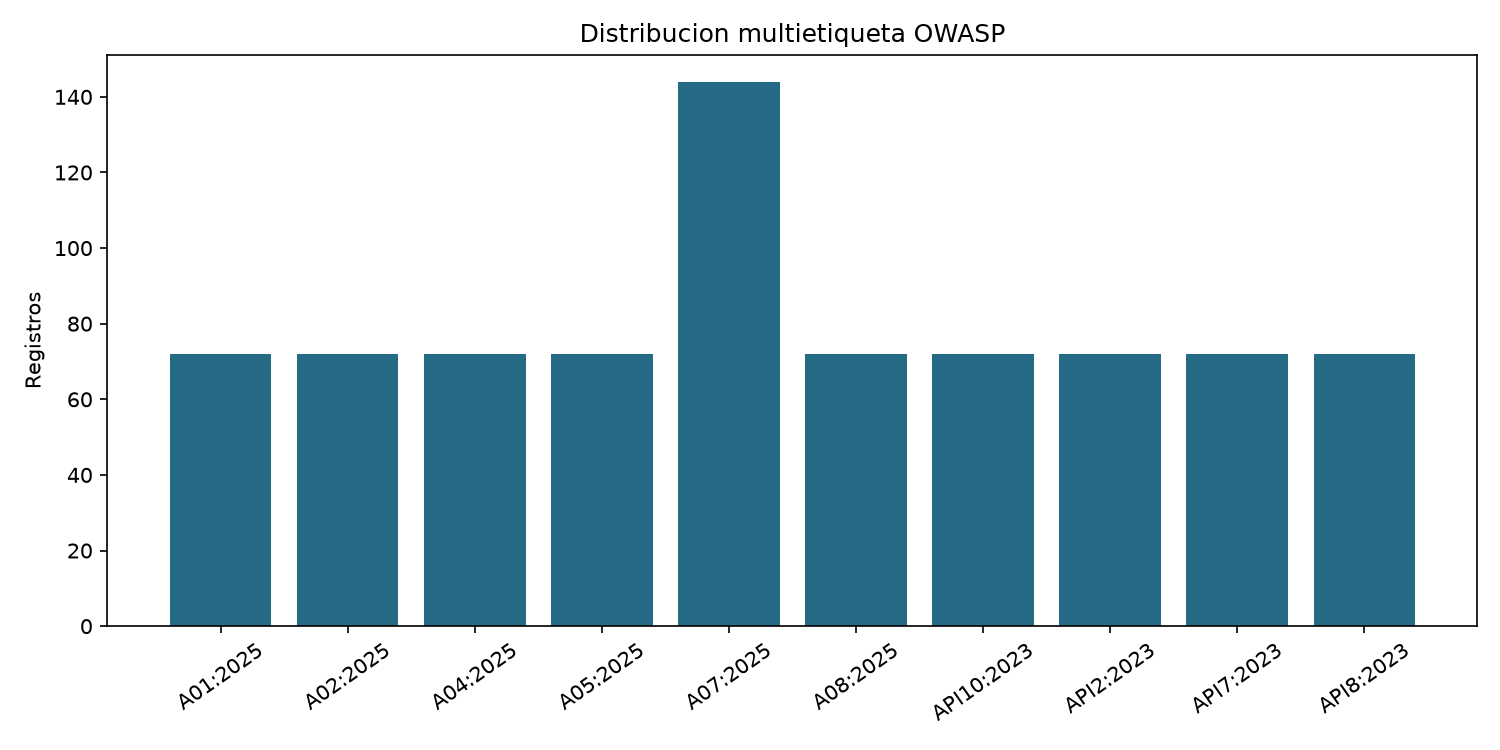

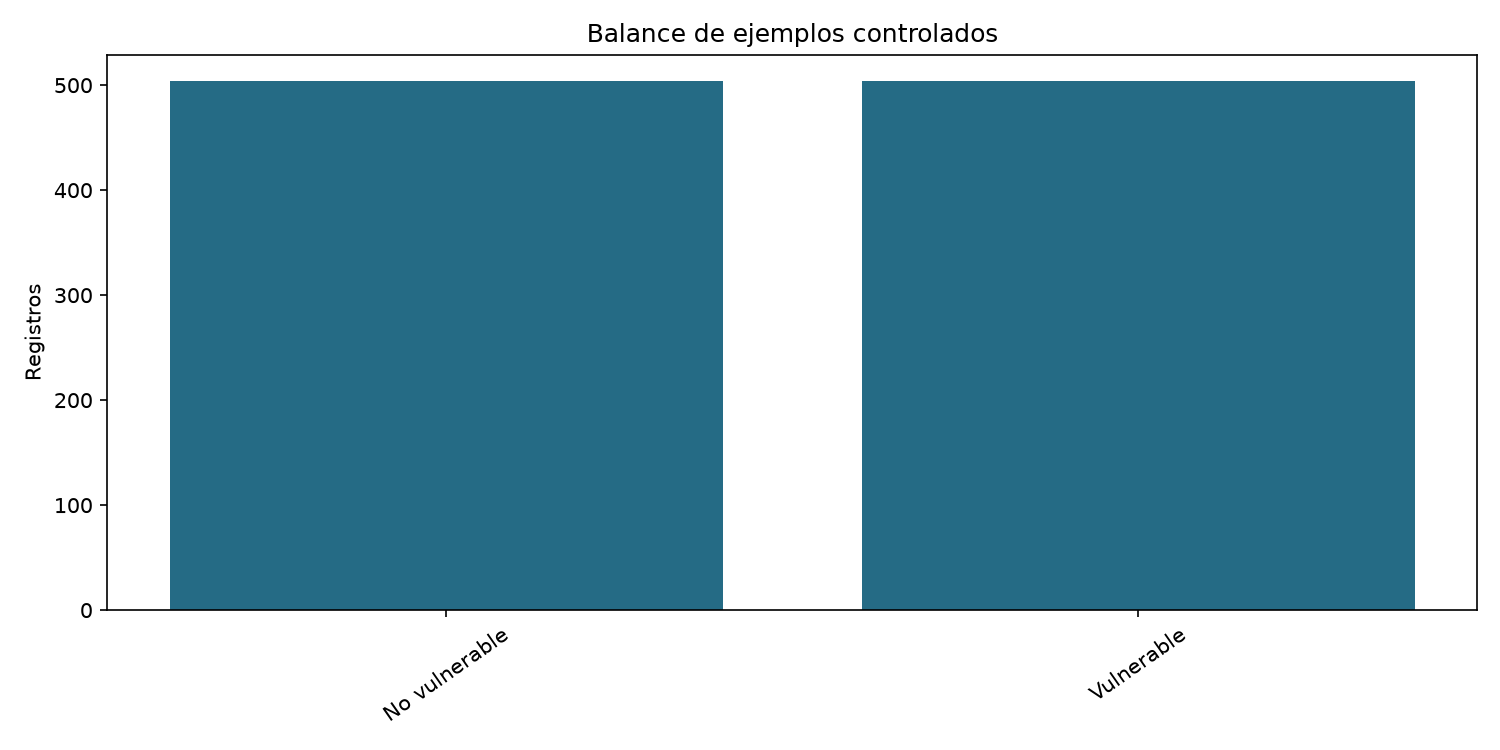

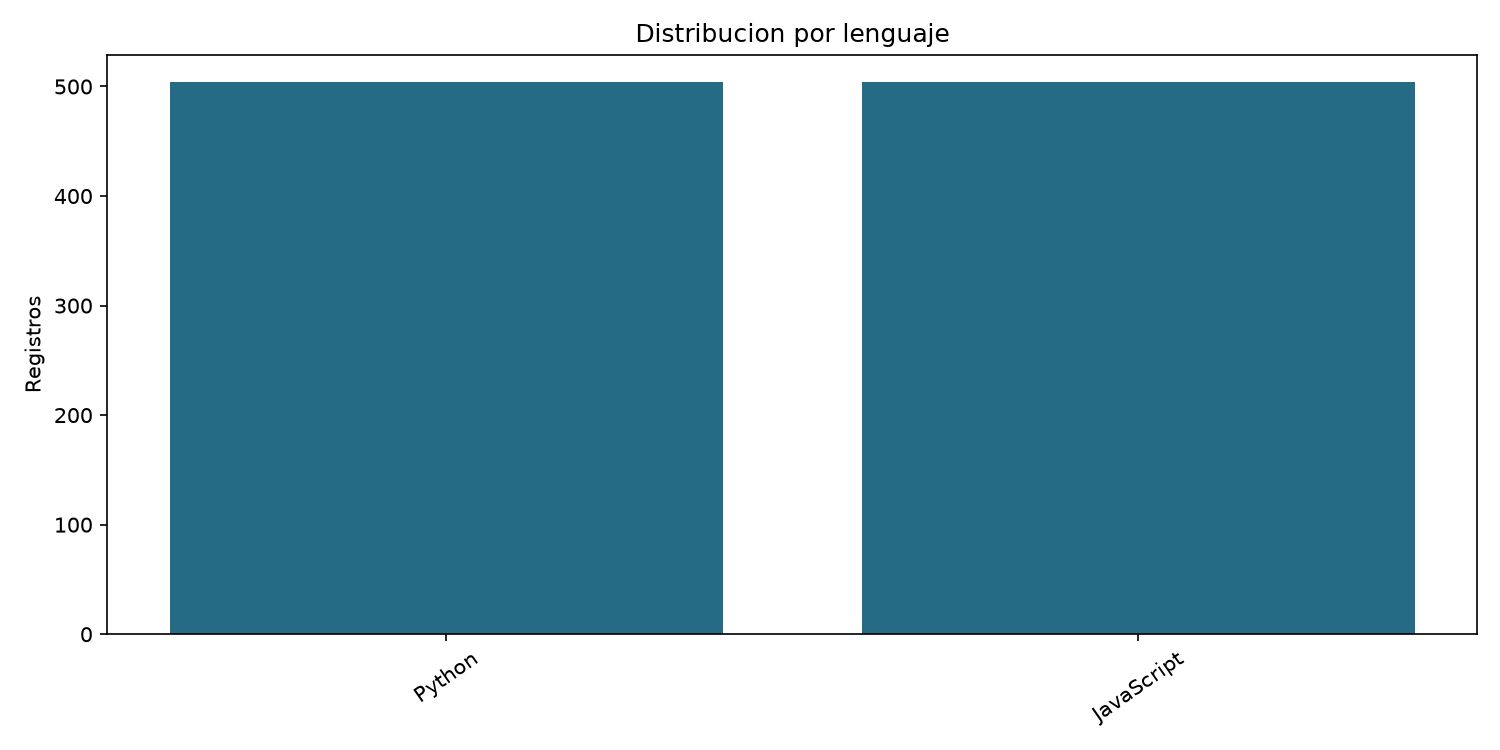

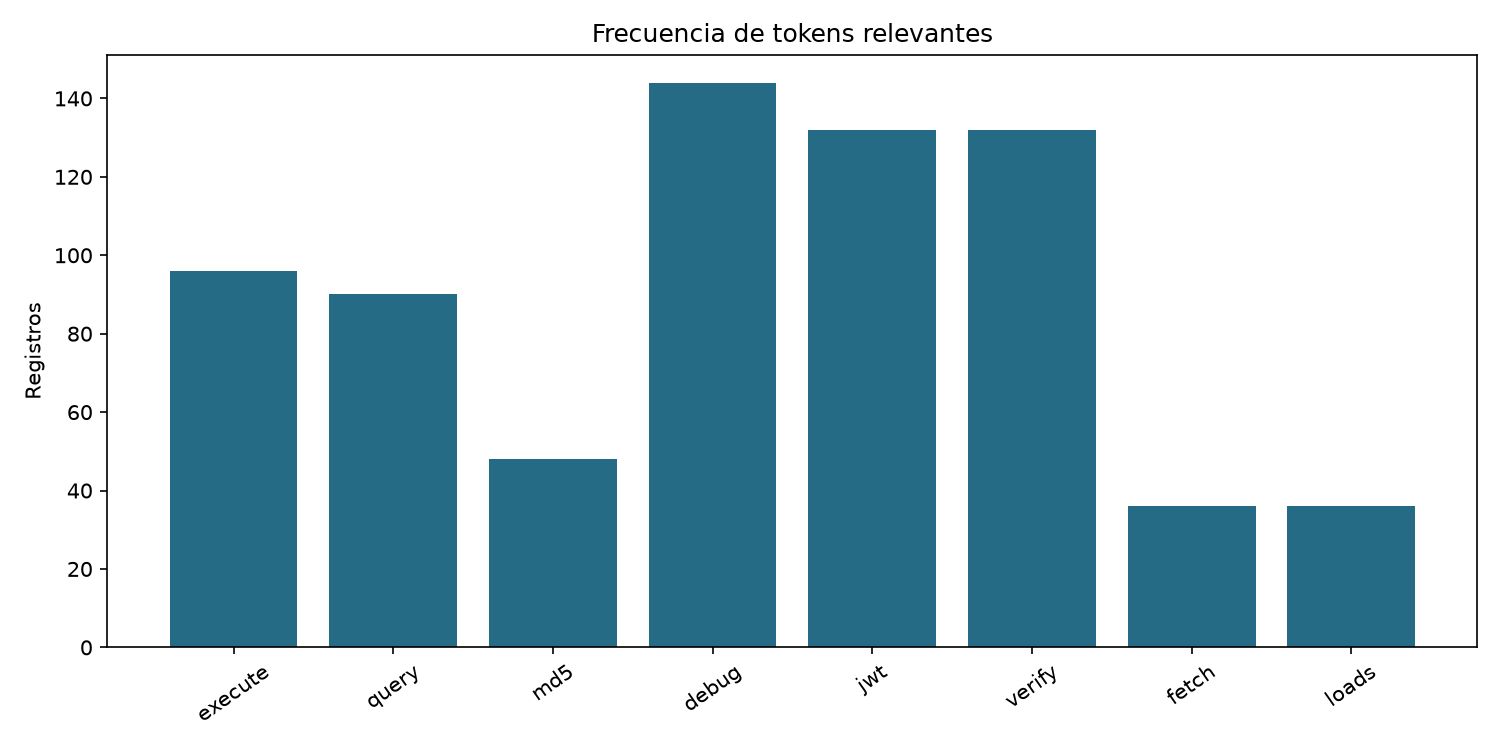

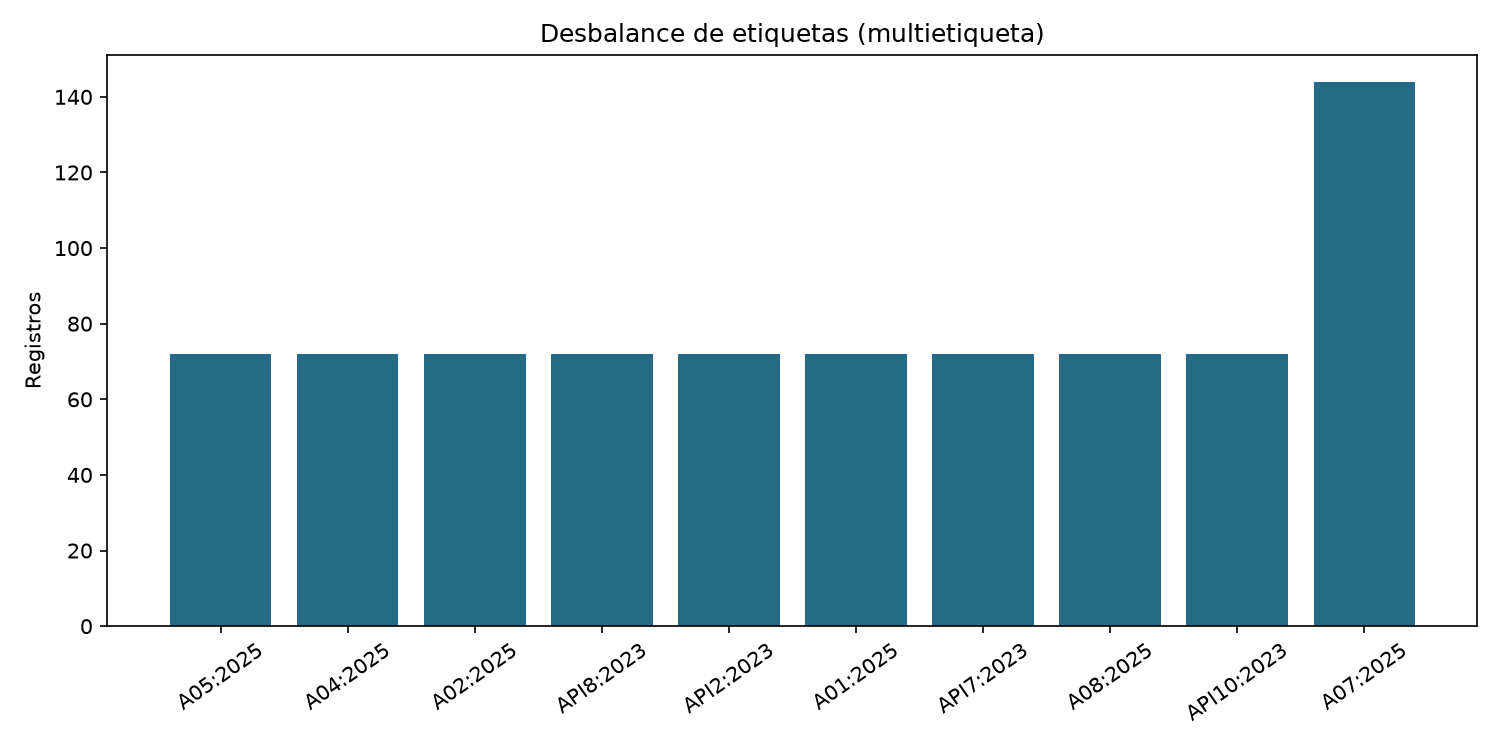

In [3]:
for chart in ['categorias','seguridad','lenguajes','patrones','desbalance']:
    display(Image(filename=str(ROOT / 'output/evaluation' / (chart + '.png'))))

Interpretación: el balance binario es exactamente 50/50 y ambos lenguajes tienen igual soporte. A07 tiene doble soporte porque agrupa JWT y TLS. Las longitudes cortas facilitan el aprendizaje local y limitan su validez para archivos grandes. Los tokens frecuentes describen el diseño de los casos, no causalidad de una vulnerabilidad. No hay duplicados exactos ni faltantes requeridos. La ausencia de CWE en casos corregidos es intencional.